# Fase 6 — Comparación final: Nested CV y test oficial (IroSvA)

Este notebook **no entrena nada**. Lee los resultados que ya guardaron los notebooks de modelos y genera las tablas y figuras de la comparación final:

0. **Nested CV (solo train):** F1 de los 5 Outer Folds de todos los modelos, en una tabla y una figura comunes;
1. tabla resumen por variante y modelo (F1-Macro, F1 de la clase irónica, AUC-ROC y AP) y F1-Macro con el test completo;
2. **curva ROC** comparativa: una figura con un panel por variante (MX, ES, CU);
3. **curva Precision-Recall** comparativa, con la misma estructura;
4. **matrices de confusión** normalizadas por clase real;
5. **falsos positivos y falsos negativos** por variante y modelo (sección 12);
6. **tuits que RoBERTuito falla en las 5 semillas**, con su texto, y si el mejor ML también los falla (sección 13).

Requisitos: haber ejecutado el test oficial de los notebooks 02 (ML), 03 (Hard Voting de ML) y 04 (BERT, DistilBERT y RoBERTuito), (el Hard Voting de Transformers se calcula aquí, en el test). Si falta alguno, el notebook lo indica y continúa con los disponibles.

**Modelo de ML en las figuras.** Para no saturar las figuras, de ML se muestra un solo modelo por variante: el de mayor F1-Macro en la **Nested CV** entre LR, RF y XGBoost (nunca se elige mirando el test). Los dos Hard Voting (ML: `HardVoting`; Transformers: `HardVotingTR`, mayoría 2 de 3 de BERT, DistilBERT y RoBERTuito, la misma regla) aparecen en la tabla y en las matrices de confusión, pero no en ROC ni Precision-Recall porque vota por clase y no produce probabilidades.

**Semillas.** Todos los modelos se evalúan en el test con las mismas 5 semillas (42, 52, 62, 72, 82): las curvas son la media de las 5 (banda = ± desviación estándar) y las métricas se reportan como media ± desviación.

> **Nombres de los modelos.** **BERT** y **DistilBERT** designan a los modelos en español conocidos como BETO (`dccuchile/bert-base-spanish-wwm-cased`) y DistilBETO (`dccuchile/distilbert-base-spanish-uncased`). Las carpetas y archivos de resultados conservan los prefijos internos `beto` y `distilbeto`.

## 1. Librerías y entorno

Importaciones y versiones de los paquetes utilizados.

In [13]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
)
import sklearn
import matplotlib

VERSIONES = {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
print("Versiones:", " | ".join(f"{k} {v}" for k, v in VERSIONES.items()))

Versiones: numpy 1.26.4 | pandas 3.0.3 | sklearn 1.8.0 | matplotlib 3.10.9


## 2. Configuración

Rutas de las predicciones de cada modelo y colores fijos para todas las figuras.

In [14]:
DATA_DIR = Path("../data")
OUT_DIR = DATA_DIR / "resultados_comparacion_final"
OUT_DIR.mkdir(parents=True, exist_ok=True)

VARIANTES = ["mx", "es", "cu"]

# Los tweets del test que también están en el train se excluyen del resultado principal;
# el F1 con los 600 tweets se reporta aparte, solo para comparar con la literatura.
EXCLUIR_REPETIDOS = True

ML_DIR = DATA_DIR / "resultados_ml_groupcv_tfidf_lr_rf_10k"
ML_PREDICCIONES = ML_DIR / "predicciones_test_ml.csv"
ML_NESTED = ML_DIR / "resumen_nested_ml.csv"
HV_PREDICCIONES = (
    DATA_DIR / "resultados_ml_hard_voting_tfidf10k" / "hard_voting_test_predicciones.csv"
)

# Carpeta de resultados y RUN_TAG de cada Transformer.
TRANSFORMERS = {
    "BERT": (DATA_DIR / "resultados_beto_grouped_5x3_tpe20", "beto", "b5x3t20"),
    "DistilBERT": (
        DATA_DIR / "resultados_distilbeto_grouped_5x3_tpe20",
        "distilbeto",
        "d5x3t20",
    ),
    "RoBERTuito": (
        DATA_DIR / "resultados_robertuito_grouped_5x3_tpe20",
        "robertuito",
        "r5x3t20",
    ),
}

# Orden y color fijos en todas las figuras.
COLORES = {
    "LR": "#8c564b",
    "RF": "#7f7f7f",
    "XGBoost": "#bcbd22",
    "HardVoting": "#e377c2",
    "BERT": "#1f77b4",
    "DistilBERT": "#ff7f0e",
    "RoBERTuito": "#2ca02c",
    "HardVotingTR": "#9467bd",
}
print(f"[CONFIG][Comparación] salida={OUT_DIR.resolve()}")

[CONFIG][Comparación] salida=/Users/taniac/Developer/DeteccionDeSarcasmo/data/resultados_comparacion_final


## 3. Nested CV: Outer Folds de todos los modelos (solo train)

Reúne en una sola tabla los 5 Outer Folds de LR, RF, XGBoost, Hard Voting de ML, BERT, DistilBERT y RoBERTuito (el Hard Voting de Transformers no tiene Nested CV; ver `05_Votacion_Transformers.ipynb`), leídos de los CSV que guarda cada notebook. Es la comparación principal del desarrollo y no usa el test oficial.

- tabla `nested_cv_resumen.csv`: media ± desviación por variante y modelo;
- tabla `nested_cv_outer_folds.csv`: F1-Macro de cada Outer Fold (una columna por fold);
- figura `nested_cv_todos_los_modelos.png/.pdf`: punto grande = media, línea = ± d.e., puntos huecos = cada Outer Fold.

Los folds de ML y de cada Transformer no son idénticos (cada modelo construye sus grupos), por lo que la comparación es descriptiva.

,Variante,Modelo,F1-Macro,F1 irónico,Folds
0,MX,LR,0.645 ± 0.015,0.531 ± 0.024,5
1,MX,RF,0.631 ± 0.020,0.509 ± 0.029,5
2,MX,XGBoost,0.599 ± 0.014,0.461 ± 0.031,5
3,MX,HardVoting,0.633 ± 0.013,0.507 ± 0.017,5
4,MX,BERT,0.632 ± 0.025,0.577 ± 0.017,5
5,MX,DistilBERT,0.652 ± 0.026,0.573 ± 0.034,5
6,MX,RoBERTuito,0.710 ± 0.020,0.625 ± 0.025,5
7,ES,LR,0.702 ± 0.016,0.612 ± 0.030,5
8,ES,RF,0.696 ± 0.030,0.602 ± 0.034,5
9,ES,XGBoost,0.685 ± 0.016,0.588 ± 0.024,5


outer_1  outer_2  outer_3  outer_4  outer_5
variante modelo                                                 
mx       LR           0.6291   0.6511   0.6674   0.6403   0.6371
         RF           0.6501   0.5993   0.6319   0.6443   0.6281
         XGBoost      0.6046   0.5981   0.6052   0.6114   0.5763
         HardVoting   0.6397   0.6109   0.6338   0.6399   0.6409
         BERT         0.6239   0.6046   0.6727   0.6302   0.6306
         DistilBERT   0.6508   0.6884   0.6301   0.6637   0.6247
         RoBERTuito   0.7036   0.7268   0.6789   0.7282   0.7112
es       LR           0.6952   0.7012   0.6985   0.7291   0.6882
         RF           0.7252   0.7038   0.7085   0.6956   0.6463
         XGBoost      0.6892   0.6624   0.6987   0.6997   0.6735
         HardVoting   0.7158   0.7039   0.7311   0.7086   0.6819
         BERT         0.7452   0.7382   0.7318   0.7442   0.7278
         DistilBERT   0.7434   0.7171   0.7139   0.6944   0.7789
         RoBERTuito   0.7708   0.7480   0.7431   0.7319   0.7998
cu       LR           0.6368   0.6658   0.6676   0.6446   0.6782
         RF           0.6726   0.6560   0.6201   0.6518   0.7036
         XGBoost      0.6694   0.6284   0.6457   0.6279   0.6473
         HardVoting   0.6648   0.6478   0.6393   0.6564   0.6986
         BERT         0.7256   0.7019   0.7352   0.7453   0.7395
         DistilBERT   0.7287   0.6953   0.7395   0.7322   0.7122
         RoBERTuito   0.7459   0.7159   0.7621   0.7401   0.7587

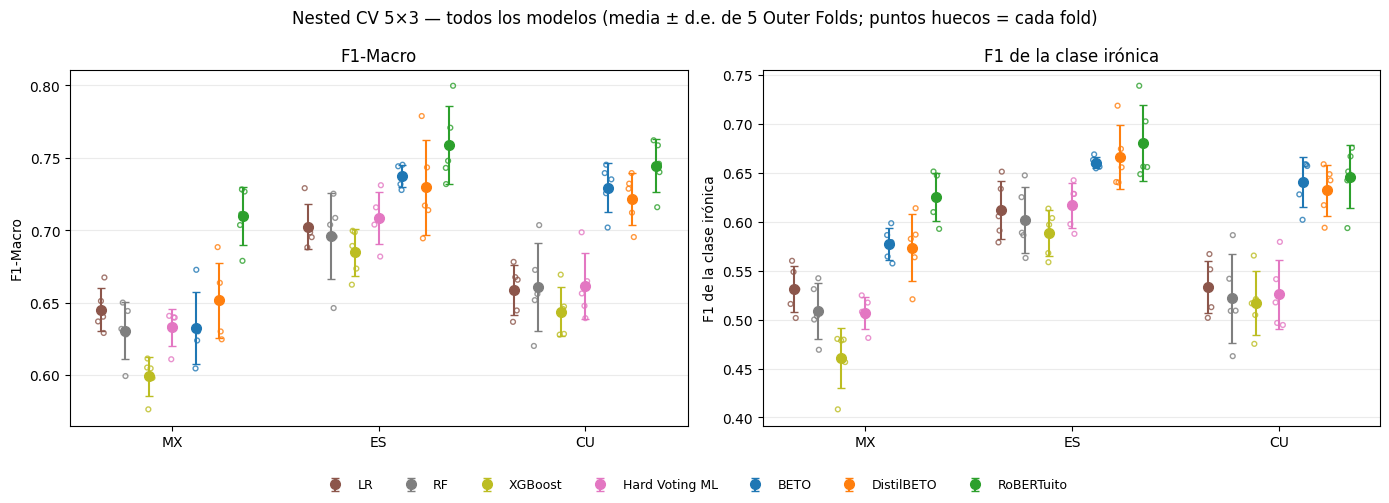

In [15]:
COLUMNAS_OUTER = ["variante", "modelo", "outer_fold", "outer_f1_macro", "outer_f1_clase_1"]
ETIQUETA_VOTO = {"HardVoting": "Hard Voting ML", "HardVotingTR": "Hard Voting Transformers"}
partes_outer = []

ruta = ML_DIR / "outer_folds_ml.csv"
if ruta.exists():
    partes_outer.append(pd.read_csv(ruta)[COLUMNAS_OUTER])
else:
    print(f"AVISO: falta {ruta} (Nested CV de ML no ejecutada).")

ruta = HV_PREDICCIONES.parent / "hard_voting_outer_folds.csv"
if ruta.exists():
    partes_outer.append(pd.read_csv(ruta)[COLUMNAS_OUTER])
else:
    print(f"AVISO: falta {ruta} (Nested CV de Hard Voting no ejecutada).")

for nombre, (carpeta, prefijo, _) in TRANSFORMERS.items():
    for variante in VARIANTES:
        ruta = carpeta / f"{prefijo}_nestedcv_detalle_{variante}.csv"
        if not ruta.exists():
            print(f"AVISO: falta {ruta} (Nested CV de {nombre} no ejecutada).")
            continue
        d = pd.read_csv(ruta).rename(
            columns={"f1_outer": "outer_f1_macro", "f1_outer_clase_1": "outer_f1_clase_1"}
        )
        d["modelo"] = nombre
        d["variante"] = variante
        partes_outer.append(d[COLUMNAS_OUTER])

ORDEN_NESTED = ["LR", "RF", "XGBoost", "HardVoting", *TRANSFORMERS]
COLORES_NESTED = COLORES

if not partes_outer:
    print("Todavía no hay resultados de Nested CV.")
else:
    OUTER = pd.concat(partes_outer, ignore_index=True)
    OUTER["modelo"] = pd.Categorical(OUTER["modelo"], ORDEN_NESTED, ordered=True)
    OUTER["variante"] = pd.Categorical(OUTER["variante"], VARIANTES, ordered=True)

    # --- tablas ---
    resumen_nested = (
        OUTER.groupby(["variante", "modelo"], observed=True)
        .agg(
            f1_macro_mean=("outer_f1_macro", "mean"),
            f1_macro_std=("outer_f1_macro", "std"),
            f1_ironia_mean=("outer_f1_clase_1", "mean"),
            f1_ironia_std=("outer_f1_clase_1", "std"),
            n_folds=("outer_fold", "nunique"),
        )
        .reset_index()
    )
    resumen_nested.to_csv(OUT_DIR / "nested_cv_resumen.csv", index=False)
    por_fold = OUTER.pivot_table(
        index=["variante", "modelo"], columns="outer_fold", values="outer_f1_macro", observed=True
    )
    por_fold.columns = [f"outer_{int(c)}" for c in por_fold.columns]
    por_fold.reset_index().to_csv(OUT_DIR / "nested_cv_outer_folds.csv", index=False)

    display(
        pd.DataFrame(
            {
                "Variante": resumen_nested["variante"].astype(str).str.upper(),
                "Modelo": resumen_nested["modelo"].astype(str),
                "F1-Macro": [
                    f"{m:.3f} ± {s:.3f}"
                    for m, s in zip(resumen_nested["f1_macro_mean"], resumen_nested["f1_macro_std"])
                ],
                "F1 irónico": [
                    f"{m:.3f} ± {s:.3f}"
                    for m, s in zip(
                        resumen_nested["f1_ironia_mean"], resumen_nested["f1_ironia_std"]
                    )
                ],
                "Folds": resumen_nested["n_folds"],
            }
        )
    )
    display(por_fold.round(4))

    # --- figura ---
    modelos_presentes = [m for m in ORDEN_NESTED if (OUTER["modelo"] == m).any()]
    separacion = 0.8 / max(1, len(modelos_presentes))
    rng_fig = np.random.default_rng(42)  # solo para separar los puntos de cada fold
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), squeeze=False)
    for ax, (col, titulo) in zip(
        axes[0], [("outer_f1_macro", "F1-Macro"), ("outer_f1_clase_1", "F1 de la clase irónica")]
    ):
        for k, modelo in enumerate(modelos_presentes):
            for j, variante in enumerate(VARIANTES):
                valores = OUTER.loc[
                    (OUTER["variante"] == variante) & (OUTER["modelo"] == modelo), col
                ].to_numpy()
                if len(valores) == 0:
                    continue
                x = j + (k - (len(modelos_presentes) - 1) / 2) * separacion
                ax.scatter(
                    x + rng_fig.uniform(-0.02, 0.02, len(valores)),
                    valores,
                    s=12,
                    facecolors="none",
                    edgecolors=COLORES_NESTED[modelo],
                    alpha=0.8,
                    zorder=2,
                )
                ax.errorbar(
                    x,
                    valores.mean(),
                    yerr=valores.std(ddof=1) if len(valores) > 1 else 0,
                    fmt="o",
                    ms=7,
                    capsize=3,
                    color=COLORES_NESTED[modelo],
                    zorder=3,
                    label=ETIQUETA_VOTO.get(modelo, modelo) if j == 0 else None,
                )
        ax.set_xticks(range(len(VARIANTES)), [v.upper() for v in VARIANTES])
        ax.set_title(titulo)
        ax.set_ylabel(titulo)
        ax.grid(axis="y", alpha=0.25)
    manejadores, etiquetas = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        manejadores, etiquetas, loc="lower center", ncol=len(etiquetas), fontsize=9, frameon=False
    )
    fig.suptitle(
        "Nested CV 5×3 — todos los modelos (media ± d.e. de 5 Outer Folds; puntos huecos = cada fold)",
        fontsize=12,
    )
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.savefig(OUT_DIR / "nested_cv_todos_los_modelos.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUT_DIR / "nested_cv_todos_los_modelos.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)

### 3.1 Curvas de pérdida de los Transformers (figura para el artículo)

Una sola figura con los tres Transformers (filas) y las tres variantes (columnas), a partir del diagnóstico de convergencia de cada notebook 04 (sección 16-bis): la configuración final de cada modelo, reentrenada en 3 folds agrupados del **train oficial**, sin early stopping y con 4 evaluaciones por época. No entrena nada ni usa el test: solo lee `<modelo>_diagnostico_convergencia.csv` y `<modelo>_config_final.json`.

- **Pérdida:** entropía cruzada ponderada por clase, sin label smoothing, con el modelo en modo evaluación (sin dropout), tanto en el train del fold como en la validación. Línea = media de los 3 folds; banda = ± desviación estándar.
- **Línea punteada:** épocas con las que se entrena el modelo final (refit). La zona sombreada es posterior al refit y no se usa.

Archivos: `curvas_perdida_transformers.png/.pdf` y `curvas_perdida_transformers_datos.csv`.

In [ ]:
import json

from IPython.display import Image

NOMBRES_VARIANTE = {"mx": "México", "es": "España", "cu": "Cuba"}
COLOR_TRAIN, COLOR_VAL = "#1f77b4", "#ff7f0e"

partes = []
for nombre, (carpeta, prefijo, _) in TRANSFORMERS.items():
    diag = pd.read_csv(carpeta / f"{prefijo}_diagnostico_convergencia.csv")
    cfg = json.loads((carpeta / f"{prefijo}_config_final.json").read_text(encoding="utf-8"))
    for variante in VARIANTES:
        d = diag[diag["variante"] == variante]
        if d["inner_fold"].nunique() != 3:
            raise ValueError(f"{nombre} {variante}: el diagnóstico debe tener 3 folds.")
        media = d.groupby("epoch_r", as_index=False).agg(
            train_loss=("train_loss", "mean"), train_std=("train_loss", "std"),
            val_loss=("val_loss", "mean"), val_std=("val_loss", "std"), n_folds=("inner_fold", "nunique"))
        media.insert(0, "variante", variante)
        media.insert(0, "modelo", nombre)
        media["epocas_refit"] = int(cfg[variante]["refit_epochs"])
        partes.append(media)
CURVAS_PERDIDA = pd.concat(partes, ignore_index=True)
CURVAS_PERDIDA.to_csv(OUT_DIR / "curvas_perdida_transformers_datos.csv", index=False)

fig, axes = plt.subplots(len(TRANSFORMERS), len(VARIANTES), figsize=(4.4 * len(VARIANTES), 2.9 * len(TRANSFORMERS)),
                         sharex=True, sharey=True, squeeze=False)
for i, nombre in enumerate(TRANSFORMERS):
    for j, variante in enumerate(VARIANTES):
        ax = axes[i, j]
        c = CURVAS_PERDIDA[(CURVAS_PERDIDA["modelo"] == nombre) & (CURVAS_PERDIDA["variante"] == variante)]
        for col, std, color in [("train_loss", "train_std", COLOR_TRAIN), ("val_loss", "val_std", COLOR_VAL)]:
            ax.plot(c["epoch_r"], c[col], color=color, linewidth=1.8)
            ax.fill_between(c["epoch_r"], c[col] - c[std], c[col] + c[std], color=color, alpha=0.15, linewidth=0)
        refit, fin = int(c["epocas_refit"].iloc[0]), c["epoch_r"].max()
        ax.axvline(refit, color="0.25", linestyle=":", linewidth=1.2)
        if refit < fin:
            ax.axvspan(refit, fin, color="0.6", alpha=0.15, linewidth=0)
        ax.set_xlim(0, fin)
        ax.set_xticks(range(int(fin) + 1))
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.25)
        if i == 0:
            ax.set_title(NOMBRES_VARIANTE.get(variante, variante.upper()))
        if j == 0:
            ax.set_ylabel(f"{nombre}\nPérdida")
        if i == len(TRANSFORMERS) - 1:
            ax.set_xlabel("Época")
fig.legend(
    [plt.Line2D([], [], color=COLOR_TRAIN, linewidth=1.8), plt.Line2D([], [], color=COLOR_VAL, linewidth=1.8),
     plt.Line2D([], [], color="0.25", linestyle=":", linewidth=1.2)],
    ["Entrenamiento", "Validación", "Épocas del entrenamiento final"],
    loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(OUT_DIR / "curvas_perdida_transformers.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "curvas_perdida_transformers.pdf", bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT_DIR / "curvas_perdida_transformers.png")))

## 4. Carga y verificación de predicciones

Todas las predicciones se unifican en una sola tabla con columnas `variante`, `modelo`, `seed`, `ID`, `y_true`, `y_pred` y `prob_ironia` (vacía para los dos Hard Voting). `HardVotingTR` se calcula aquí, semilla por semilla, con la mayoría 2 de 3 de las predicciones de BERT, DistilBERT y RoBERTuito de esa semilla (igual que el Hard Voting de ML en el notebook 03). Se verifica que cada modelo tenga los 600 textos por variante y semilla, con los mismos IDs y etiquetas que el resto.

In [16]:
partes = []

if ML_PREDICCIONES.exists():
    ml = pd.read_csv(ML_PREDICCIONES, dtype={"ID": str})
    if "seed" not in ml.columns:
        ml["seed"] = 0
    partes.append(ml)
else:
    print(f"AVISO: falta {ML_PREDICCIONES} (test de ML no ejecutado).")

if HV_PREDICCIONES.exists():
    hv = pd.read_csv(HV_PREDICCIONES, dtype={"ID": str})
    if "seed" not in hv.columns:
        hv["seed"] = 0
    hv["prob_ironia"] = np.nan
    partes.append(hv)
else:
    print(f"AVISO: falta {HV_PREDICCIONES} (test de Hard Voting no ejecutado).")

for nombre, (carpeta, prefijo, _) in TRANSFORMERS.items():
    ruta = carpeta / f"{prefijo}_test_probabilidades.csv"
    if ruta.exists():
        d = pd.read_csv(ruta, dtype={"ID": str})
        d["modelo"] = nombre
        partes.append(d)
    else:
        print(f"AVISO: falta {ruta} (test de {nombre} no ejecutado).")

# Hard Voting de Transformers: mayoría 2 de 3 de las predicciones de la MISMA semilla (igual que el notebook 03).
tr_partes = [p for p in partes if "modelo" in p.columns and p["modelo"].iloc[0] in TRANSFORMERS]
if len(tr_partes) == len(TRANSFORMERS):
    tr = pd.concat(tr_partes, ignore_index=True)
    votos = tr.pivot_table(index=["variante", "seed", "ID"], columns="modelo", values="y_pred", aggfunc="first")
    etiquetas_tr = tr.drop_duplicates(["variante", "seed", "ID"]).set_index(["variante", "seed", "ID"])["y_true"]
    if votos[list(TRANSFORMERS)].isna().any().any():
        raise ValueError("Hard Voting de Transformers: falta la predicción de algún modelo para alguna semilla/ID.")
    hv_tr = votos.reset_index()[["variante", "seed", "ID"]]
    hv_tr["y_pred"] = (votos[list(TRANSFORMERS)].sum(axis=1).to_numpy() >= 2).astype(int)
    hv_tr["y_true"] = etiquetas_tr.loc[votos.index].to_numpy()
    hv_tr["modelo"] = "HardVotingTR"
    hv_tr["prob_ironia"] = np.nan
    partes.append(hv_tr)
else:
    print("AVISO: faltan predicciones de algún Transformer; no se calcula el Hard Voting de Transformers.")

if not partes:
    raise FileNotFoundError(
        "No hay predicciones del test. Ejecuta primero el test oficial de los modelos."
    )

columnas = ["variante", "modelo", "seed", "ID", "y_true", "y_pred", "prob_ironia"]
PRED = pd.concat([p[columnas] for p in partes], ignore_index=True)
PRED["ID"] = PRED["ID"].astype(str)

# ---------------- verificaciones ----------------
referencia = {}
for (variante, modelo, seed), g in PRED.groupby(["variante", "modelo", "seed"]):
    if len(g) != 600 or g["ID"].duplicated().any():
        raise ValueError(
            f"{variante}/{modelo}/semilla {seed}: se esperaban 600 IDs únicos, hay {len(g)}."
        )
    etiquetas = g.set_index("ID")["y_true"].sort_index()
    if variante not in referencia:
        referencia[variante] = etiquetas
    elif not etiquetas.equals(referencia[variante]):
        raise ValueError(
            f"{variante}/{modelo}/semilla {seed}: IDs o etiquetas distintos al resto de modelos."
        )

print("Predicciones verificadas:")
display(
    PRED.groupby(["variante", "modelo"])
    .agg(semillas=("seed", "nunique"), textos=("ID", "nunique"))
    .reset_index()
)

Predicciones verificadas:


,variante,modelo,semillas,textos
0,cu,BERT,5,600
1,cu,DistilBERT,5,600
2,cu,HardVoting,5,600
3,cu,HardVotingTR,5,600
4,cu,LR,5,600
5,cu,RF,5,600
6,cu,RoBERTuito,5,600
7,cu,XGBoost,5,600
8,es,BERT,5,600
9,es,DistilBERT,5,600


## 5. Textos del test que coinciden con el train (conjunto común)

Para que el análisis de sensibilidad sea **igual para todos los modelos**, se usa un único conjunto de textos excluidos por variante: la unión de las coincidencias detectadas por los tres Transformers (mismo `MESSAGE` original o misma secuencia de tokens de entrada) más las coincidencias exactas del `MESSAGE` original entre los CSV de train y test. Este conjunto solo se usa para recalcular el F1; no interviene en ninguna decisión de los modelos.

**Resultado principal sin repetidos.** Con `EXCLUIR_REPETIDOS = True` (por defecto), estos tweets se **eliminan** del test para todas las tablas y figuras siguientes, porque el modelo pudo haberlos visto al entrenar (contaminación train ↔ test). El F1-Macro con los 600 tweets se reporta en una columna aparte (`F1-Macro test completo (600)`), solo para comparar con los trabajos previos sobre IroSvA, que evalúan con el test completo. La diferencia entre ambos es el análisis de sensibilidad ante duplicados.

In [17]:
def colapsar(texto):
    return re.sub(r"\s+", " ", str(texto)).strip()


IDS_COINCIDENTES = {}
for variante in VARIANTES:
    ids = set()
    # Coincidencias registradas por cada Transformer en su auditoría del test.
    for nombre, (carpeta, _, run_tag) in TRANSFORMERS.items():
        auditoria = carpeta / "seguimiento" / run_tag / "completo" / "audit"
        for ruta in auditoria.glob(f"coincidencias_test_train_{variante}_*.csv"):
            ids |= set(pd.read_csv(ruta, dtype={"ID": str})["ID"].astype(str))
    # Coincidencia exacta del MESSAGE original (no depende de ningún modelo).
    ruta_tr = DATA_DIR / f"train_clean_{variante}.csv"
    ruta_te = DATA_DIR / f"test_clean_{variante}.csv"
    if ruta_tr.exists() and ruta_te.exists():
        tr = pd.read_csv(ruta_tr, dtype={"ID": str})
        te = pd.read_csv(ruta_te, dtype={"ID": str})
        originales = set(tr["MESSAGE"].map(colapsar))
        ids |= set(te.loc[te["MESSAGE"].map(colapsar).isin(originales), "ID"].astype(str))
    IDS_COINCIDENTES[variante] = ids

PRED["coincide_train"] = [
    i in IDS_COINCIDENTES.get(v, set()) for v, i in zip(PRED["variante"], PRED["ID"])
]
df_coincidencias = pd.DataFrame(
    [{"variante": v, "textos_coincidentes": len(IDS_COINCIDENTES[v])} for v in VARIANTES]
)
csv_coinc = pd.DataFrame(
    [{"variante": v, "ID": i} for v in VARIANTES for i in sorted(IDS_COINCIDENTES[v])]
)
csv_coinc.to_csv(OUT_DIR / "ids_test_coincidentes_con_train.csv", index=False)
display(df_coincidencias)

# Resultado principal sin los tweets repetidos (PRED); PRED_COMPLETO conserva los 600 por variante.
PRED_COMPLETO = PRED.copy()
if EXCLUIR_REPETIDOS:
    PRED = PRED[~PRED["coincide_train"]].reset_index(drop=True)
print("Tweets por variante en el análisis principal:",
      PRED.drop_duplicates(["variante", "ID"]).groupby("variante").size().reindex(VARIANTES).to_dict())

,variante,textos_coincidentes
0,mx,2
1,es,23
2,cu,1


Tweets por variante en el análisis principal: {'mx': 598, 'es': 577, 'cu': 599}


## 6. Selección del modelo de ML para las figuras

Se elige por variante el modelo de ML con mayor F1-Macro en la **Nested CV** (solo train), entre los que producen probabilidades.

In [18]:
ML_EN_FIGURAS = {}
if ML_NESTED.exists() and (PRED["modelo"].isin(["LR", "RF", "XGBoost"])).any():
    nested = pd.read_csv(ML_NESTED)
    for variante in VARIANTES:
        candidatos = nested[
            (nested["variante"] == variante) & nested["modelo"].isin(["LR", "RF", "XGBoost"])
        ]
        if not candidatos.empty:
            fila = candidatos.sort_values("f1_nested_mean", ascending=False).iloc[0]
            ML_EN_FIGURAS[variante] = fila["modelo"]
            print(
                f"{variante.upper()}: {fila['modelo']} (F1 Nested CV = {fila['f1_nested_mean']:.4f})"
            )
else:
    print("Sin resultados de ML: las figuras mostrarán solo los Transformers.")


def modelos_en_figura(variante):
    """(etiqueta en la figura, nombre del modelo en PRED) en orden fijo."""
    salida = []
    if variante in ML_EN_FIGURAS:
        salida.append((f"ML ({ML_EN_FIGURAS[variante]})", ML_EN_FIGURAS[variante]))
    for nombre in TRANSFORMERS:
        if ((PRED["variante"] == variante) & (PRED["modelo"] == nombre)).any():
            salida.append((nombre, nombre))
    return salida


def color(etiqueta):
    """Color fijo por modelo; «ML (LR)» usa el color de LR."""
    if etiqueta.startswith("ML ("):
        etiqueta = etiqueta[len("ML (") : -1]
    etiqueta = {"Hard Voting ML": "HardVoting", "Hard Voting": "HardVoting", "Hard Voting Transformers": "HardVotingTR"}.get(etiqueta, etiqueta)
    return COLORES[etiqueta]

MX: LR (F1 Nested CV = 0.6450)
ES: LR (F1 Nested CV = 0.7024)
CU: RF (F1 Nested CV = 0.6608)


## 7. Tabla resumen del test oficial

Para cada semilla se calculan las métricas y luego la media ± desviación (todos los modelos con 5 semillas: 42, 52, 62, 72 y 82). Todas las métricas se calculan **sin los tweets repetidos** (sección 5); `F1-Macro test completo (600)` usa los 600 tweets de cada variante, solo para la comparación con la literatura.

In [19]:
filas = []
for (variante, modelo, seed), completo in PRED_COMPLETO.groupby(["variante", "modelo", "seed"]):
    limpio = completo[~completo["coincide_train"]]
    g = limpio if EXCLUIR_REPETIDOS else completo  # base del resultado principal
    tiene_prob = g["prob_ironia"].notna().all()
    filas.append(
        {
            "variante": variante,
            "modelo": modelo,
            "seed": seed,
            "f1_macro": f1_score(g["y_true"], g["y_pred"], average="macro"),
            "f1_ironia": f1_score(g["y_true"], g["y_pred"], pos_label=1, zero_division=0),
            "f1_macro_sin_coincidencias": f1_score(
                limpio["y_true"], limpio["y_pred"], average="macro"
            ),
            "f1_macro_test_completo": f1_score(completo["y_true"], completo["y_pred"], average="macro"),
            "auc_roc": roc_auc_score(g["y_true"], g["prob_ironia"]) if tiene_prob else np.nan,
            "average_precision": (
                average_precision_score(g["y_true"], g["prob_ironia"]) if tiene_prob else np.nan
            ),
        }
    )
METRICAS = pd.DataFrame(filas)

metricas = ["f1_macro", "f1_ironia", "f1_macro_sin_coincidencias", "f1_macro_test_completo", "auc_roc", "average_precision"]
resumen = METRICAS.groupby(["variante", "modelo"])[metricas].agg(["mean", "std"])
resumen.columns = [f"{m}_{e}" for m, e in resumen.columns]
resumen = resumen.reset_index()
resumen["n_semillas"] = METRICAS.groupby(["variante", "modelo"])["seed"].nunique().to_numpy()

orden_modelos = ["LR", "RF", "XGBoost", "HardVoting", *TRANSFORMERS, "HardVotingTR"]
resumen["modelo"] = pd.Categorical(resumen["modelo"], orden_modelos, ordered=True)
resumen["variante"] = pd.Categorical(resumen["variante"], VARIANTES, ordered=True)
resumen = resumen.sort_values(["variante", "modelo"]).reset_index(drop=True)
resumen.to_csv(OUT_DIR / "tabla_resumen_test.csv", index=False)
METRICAS.to_csv(OUT_DIR / "metricas_test_por_semilla.csv", index=False)


def media_std(m, s):
    if pd.isna(m):
        return "—"
    return f"{m:.3f}" if pd.isna(s) else f"{m:.3f} ± {s:.3f}"


tabla_informe = pd.DataFrame(
    {
        "Variante": resumen["variante"].astype(str).str.upper(),
        "Modelo": resumen["modelo"].astype(str),
        "F1-Macro": [
            media_std(m, s) for m, s in zip(resumen["f1_macro_mean"], resumen["f1_macro_std"])
        ],
        "F1 irónico": [
            media_std(m, s) for m, s in zip(resumen["f1_ironia_mean"], resumen["f1_ironia_std"])
        ],
        "F1-Macro test completo (600)": [
            media_std(m, s)
            for m, s in zip(
                resumen["f1_macro_test_completo_mean"],
                resumen["f1_macro_test_completo_std"],
            )
        ],
        "AUC-ROC": [
            media_std(m, s) for m, s in zip(resumen["auc_roc_mean"], resumen["auc_roc_std"])
        ],
        "AP": [
            media_std(m, s)
            for m, s in zip(resumen["average_precision_mean"], resumen["average_precision_std"])
        ],
    }
)
tabla_informe.to_csv(OUT_DIR / "tabla_resumen_test_informe.csv", index=False)
display(tabla_informe)

,Variante,Modelo,F1-Macro,F1 irónico,F1-Macro test completo (600),AUC-ROC,AP
0,MX,LR,0.693 ± 0.000,0.589 ± 0.000,0.692 ± 0.000,0.742 ± 0.000,0.597 ± 0.000
1,MX,RF,0.656 ± 0.006,0.548 ± 0.008,0.654 ± 0.006,0.734 ± 0.005,0.569 ± 0.006
2,MX,XGBoost,0.647 ± 0.012,0.533 ± 0.018,0.647 ± 0.012,0.721 ± 0.004,0.537 ± 0.006
3,MX,HardVoting,0.667 ± 0.007,0.557 ± 0.010,0.665 ± 0.008,—,—
4,MX,BERT,0.716 ± 0.017,0.651 ± 0.003,0.715 ± 0.017,0.816 ± 0.004,0.670 ± 0.006
5,MX,DistilBERT,0.703 ± 0.006,0.624 ± 0.005,0.702 ± 0.006,0.792 ± 0.005,0.628 ± 0.012
6,MX,RoBERTuito,0.754 ± 0.004,0.685 ± 0.003,0.753 ± 0.004,0.849 ± 0.005,0.727 ± 0.009
7,MX,HardVotingTR,0.741 ± 0.006,0.672 ± 0.008,0.740 ± 0.006,—,—
8,ES,LR,0.712 ± 0.000,0.637 ± 0.000,0.719 ± 0.000,0.797 ± 0.000,0.670 ± 0.000
9,ES,RF,0.707 ± 0.009,0.599 ± 0.013,0.713 ± 0.009,0.808 ± 0.002,0.663 ± 0.002


## 8. Curva ROC comparativa

Una figura con un panel por variante. En cada panel, todos los modelos evaluados sobre los mismos tweets (test sin los repetidos, sección 5). Para todos los modelos, la curva es la media de las 5 semillas (interpolada sobre una rejilla común de tasa de falsos positivos) con banda de ± desviación estándar; la leyenda muestra el AUC medio ± desviación.

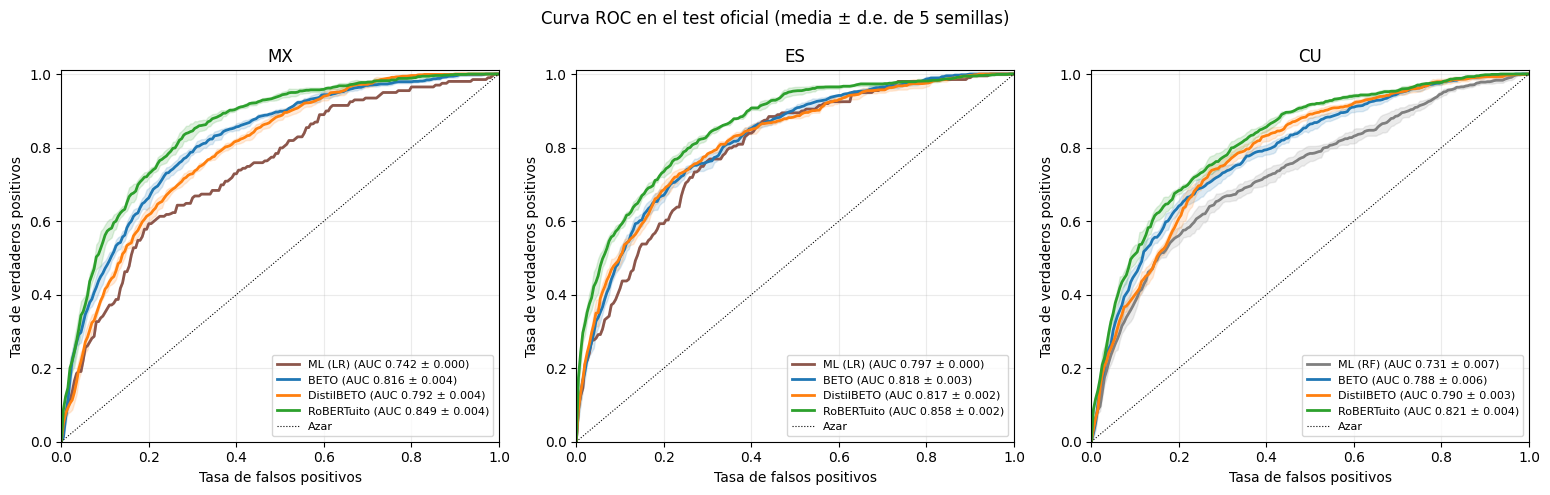

In [20]:
REJILLA = np.linspace(0, 1, 201)


def curva_media(g, tipo):
    """Curva media sobre semillas en la rejilla común."""
    curvas, areas = [], []
    for _, s in g.groupby("seed"):
        if tipo == "roc":
            x, y, _ = roc_curve(s["y_true"], s["prob_ironia"])
            interp = np.interp(REJILLA, x, y)
            interp[0] = 0.0
            areas.append(roc_auc_score(s["y_true"], s["prob_ironia"]))
        else:
            precision, recall, _ = precision_recall_curve(s["y_true"], s["prob_ironia"])
            interp = np.interp(REJILLA, recall[::-1], precision[::-1])
            areas.append(average_precision_score(s["y_true"], s["prob_ironia"]))
        curvas.append(interp)
    curvas = np.vstack(curvas)
    return curvas.mean(axis=0), curvas.std(axis=0), np.mean(areas), np.std(areas), len(areas)


def figura_comparativa(tipo):
    variantes = [v for v in VARIANTES if (PRED["variante"] == v).any()]
    fig, axes = plt.subplots(1, len(variantes), figsize=(5.2 * len(variantes), 5.0), squeeze=False)
    for ax, variante in zip(axes[0], variantes):
        for etiqueta, modelo in modelos_en_figura(variante):
            g = PRED[(PRED["variante"] == variante) & (PRED["modelo"] == modelo)]
            if g["prob_ironia"].isna().any():
                continue
            media, std, area, area_std, n = curva_media(g, tipo)
            nombre_area = "AUC" if tipo == "roc" else "AP"
            texto = f"{area:.3f}" if n == 1 else f"{area:.3f} ± {area_std:.3f}"
            ax.plot(
                REJILLA,
                media,
                color=color(etiqueta),
                lw=2,
                label=f"{etiqueta} ({nombre_area} {texto})",
            )
            if n > 1:
                ax.fill_between(
                    REJILLA,
                    np.clip(media - std, 0, 1),
                    np.clip(media + std, 0, 1),
                    color=color(etiqueta),
                    alpha=0.15,
                )
        if tipo == "roc":
            ax.plot([0, 1], [0, 1], color="black", lw=0.8, ls=":", label="Azar")
            ax.set_xlabel("Tasa de falsos positivos")
            ax.set_ylabel("Tasa de verdaderos positivos")
        else:
            prevalencia = (
                PRED.loc[PRED["variante"] == variante].drop_duplicates("ID")["y_true"].mean()
            )
            ax.axhline(
                prevalencia, color="black", lw=0.8, ls=":", label=f"Azar ({prevalencia:.2f})"
            )
            ax.set_xlabel("Recall (clase irónica)")
            ax.set_ylabel("Precisión (clase irónica)")
        ax.set_title(variante.upper())
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.01)
        ax.grid(alpha=0.25)
        ax.legend(loc="lower right" if tipo == "roc" else "upper right", fontsize=8)
    titulo = "Curva ROC" if tipo == "roc" else "Curva Precision-Recall"
    fig.suptitle(
        f"{titulo} en el test oficial (media ± d.e. de 5 semillas)", fontsize=12
    )
    fig.tight_layout()
    nombre = "curva_roc_test" if tipo == "roc" else "curva_precision_recall_test"
    fig.savefig(OUT_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUT_DIR / f"{nombre}.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)


figura_comparativa("roc")

## 9. Curva Precision-Recall comparativa

Misma estructura que la ROC. Con la clase irónica como minoría (≈ 1/3), esta curva es más sensible a las diferencias en la detección de ironía. La línea punteada es la proporción de textos irónicos (rendimiento de un clasificador al azar).

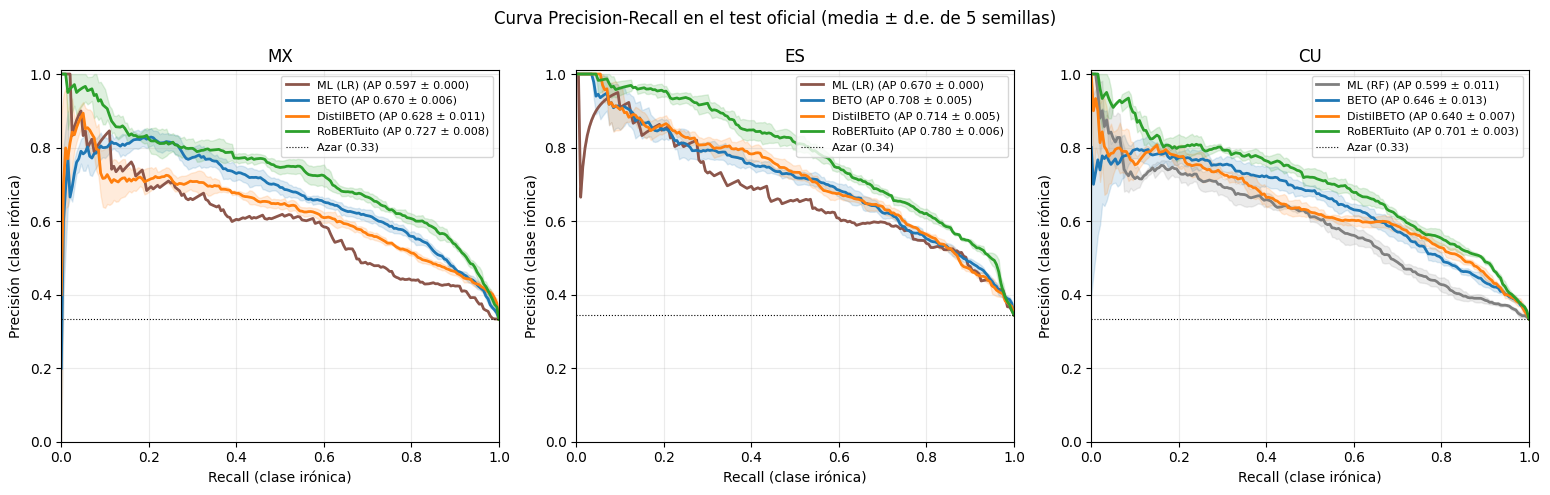

In [21]:
figura_comparativa("pr")

## 10. Matrices de confusión

Filas = modelos, columnas = variantes. Cada celda muestra el porcentaje respecto a la clase real (las filas de cada matriz suman 100 %) y, entre paréntesis, el número medio de textos. Se promedian las 5 semillas de cada modelo.

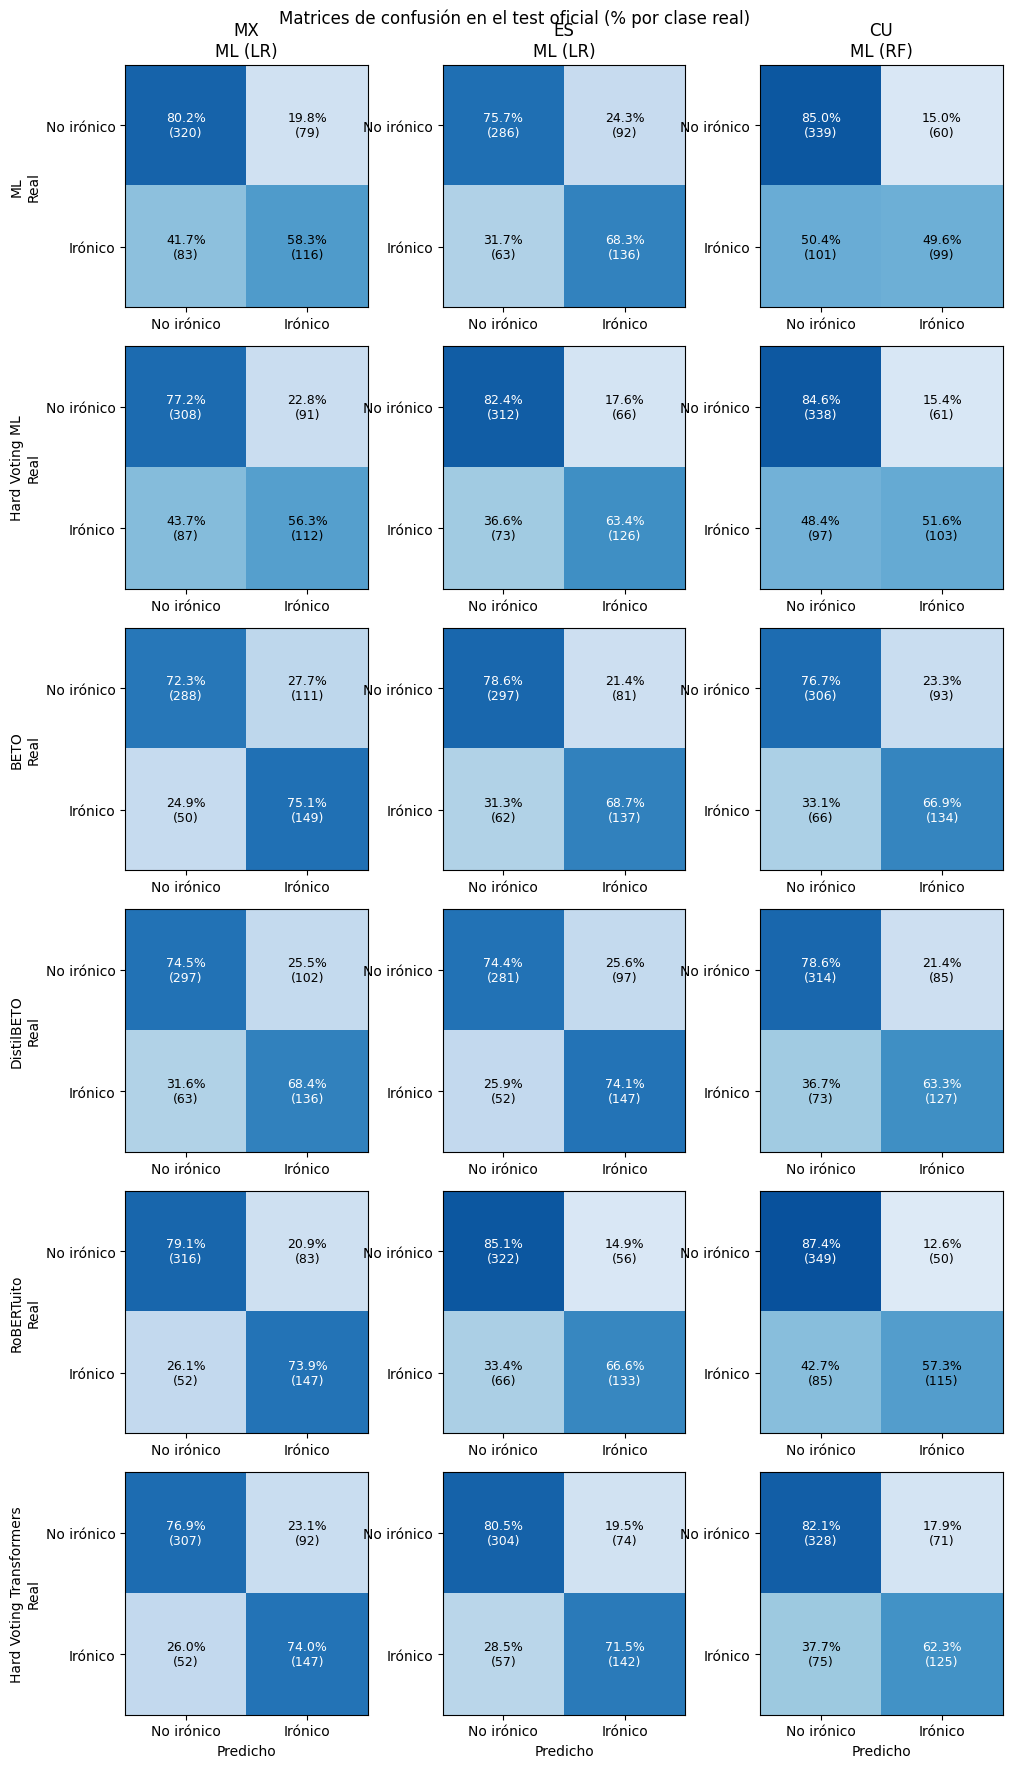

In [22]:
def modelos_en_matrices(variante):
    salida = modelos_en_figura(variante)
    if ((PRED["variante"] == variante) & (PRED["modelo"] == "HardVoting")).any():
        salida.insert(
            1 if salida and salida[0][0].startswith("ML") else 0, ("Hard Voting ML", "HardVoting")
        )
    if ((PRED["variante"] == variante) & (PRED["modelo"] == "HardVotingTR")).any():
        salida.append(("Hard Voting Transformers", "HardVotingTR"))
    return salida


variantes = [v for v in VARIANTES if (PRED["variante"] == v).any()]
etiquetas_filas = []
for v in variantes:
    for etiqueta, _ in modelos_en_matrices(v):
        clave = "ML" if etiqueta.startswith("ML") else etiqueta
        if clave not in etiquetas_filas:
            etiquetas_filas.append(clave)

fig, axes = plt.subplots(
    len(etiquetas_filas),
    len(variantes),
    figsize=(3.4 * len(variantes), 3.0 * len(etiquetas_filas)),
    squeeze=False,
)
for j, variante in enumerate(variantes):
    disponibles = {
        ("ML" if e.startswith("ML") else e): (e, m) for e, m in modelos_en_matrices(variante)
    }
    for i, clave in enumerate(etiquetas_filas):
        ax = axes[i, j]
        if clave not in disponibles:
            ax.axis("off")
            continue
        etiqueta, modelo = disponibles[clave]
        g = PRED[(PRED["variante"] == variante) & (PRED["modelo"] == modelo)]
        matrices = [
            confusion_matrix(s["y_true"], s["y_pred"], labels=[0, 1]) for _, s in g.groupby("seed")
        ]
        cuentas = np.mean(matrices, axis=0)
        porcentaje = cuentas / cuentas.sum(axis=1, keepdims=True)
        ax.imshow(porcentaje, cmap="Blues", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(
                    b,
                    a,
                    f"{100 * porcentaje[a, b]:.1f}%\n({cuentas[a, b]:.0f})",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if porcentaje[a, b] > 0.6 else "black",
                )
        ax.set_xticks([0, 1], ["No irónico", "Irónico"])
        ax.set_yticks([0, 1], ["No irónico", "Irónico"])
        if i == len(etiquetas_filas) - 1:
            ax.set_xlabel("Predicho")
        if j == 0:
            ax.set_ylabel(f"{clave}\nReal")
        if i == 0:
            # Si la primera fila es ML, se indica qué modelo se eligió en cada variante.
            ax.set_title(variante.upper() + (f"\n{etiqueta}" if clave == "ML" else ""))
fig.suptitle("Matrices de confusión en el test oficial (% por clase real)", fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "matrices_confusion_test.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "matrices_confusion_test.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)

## 11. Archivos generados

En `../data/resultados_comparacion_final/`:

- `nested_cv_resumen.csv`, `nested_cv_outer_folds.csv` y `nested_cv_todos_los_modelos.png/.pdf` — Nested CV de todos los modelos;
- `tabla_resumen_test_informe.csv` — tabla lista para el informe (media ± d.e.);
- `tabla_resumen_test.csv` y `metricas_test_por_semilla.csv` — valores numéricos completos;
- `curva_roc_test.png/.pdf` y `curva_precision_recall_test.png/.pdf`;
- `matrices_confusion_test.png/.pdf`;
- `ids_test_coincidentes_con_train.csv` — textos excluidos en el análisis de sensibilidad.

- `curvas_perdida_transformers.png/.pdf` y `curvas_perdida_transformers_datos.csv` — curvas de pérdida de los tres Transformers (sección 3.1).

Las curvas de entrenamiento de cada modelo por separado están en su notebook de Transformer (secciones 16 y 16-bis).

## 12. Falsos positivos y falsos negativos por variante

Para cada variante y modelo se cuentan, en promedio sobre las 5 semillas:

- **FP (falso positivo):** tuit **no irónico** clasificado como irónico. Tasa FP = FP / (FP + VN).
- **FN (falso negativo):** tuit **irónico** que el modelo no detectó. Tasa FN = FN / (FN + VP).

Una tasa FN alta significa que el modelo "se pierde" ironía; una tasa FP alta, que ve ironía donde no la hay. Archivos: `tabla_fp_fn_test.csv` y `fp_fn_test.png/.pdf`.

,variante,modelo,VP,VN,FP,FN,tasa_FP,tasa_FN,FP_std,FN_std
0,mx,LR,116.0,320.0,79.0,83.0,0.198,0.417,0.000,0.000
1,mx,RF,112.6,300.0,99.0,86.4,0.248,0.434,2.236,2.074
2,mx,XGBoost,107.6,301.6,97.4,91.4,0.244,0.459,1.140,4.561
3,mx,HardVoting,112.0,308.2,90.8,87.0,0.228,0.437,2.588,2.550
4,mx,BERT,149.4,288.4,110.6,49.6,0.277,0.249,25.066,11.194
5,mx,DistilBERT,136.2,297.4,101.6,62.8,0.255,0.316,12.157,6.380
6,mx,RoBERTuito,147.0,315.8,83.2,52.0,0.209,0.261,5.167,2.345
7,mx,HardVotingTR,147.2,307.0,92.0,51.8,0.231,0.260,10.977,7.120
8,es,LR,136.0,286.0,92.0,63.0,0.243,0.317,0.000,0.000
9,es,RF,108.8,322.6,55.4,90.2,0.147,0.453,2.191,3.421


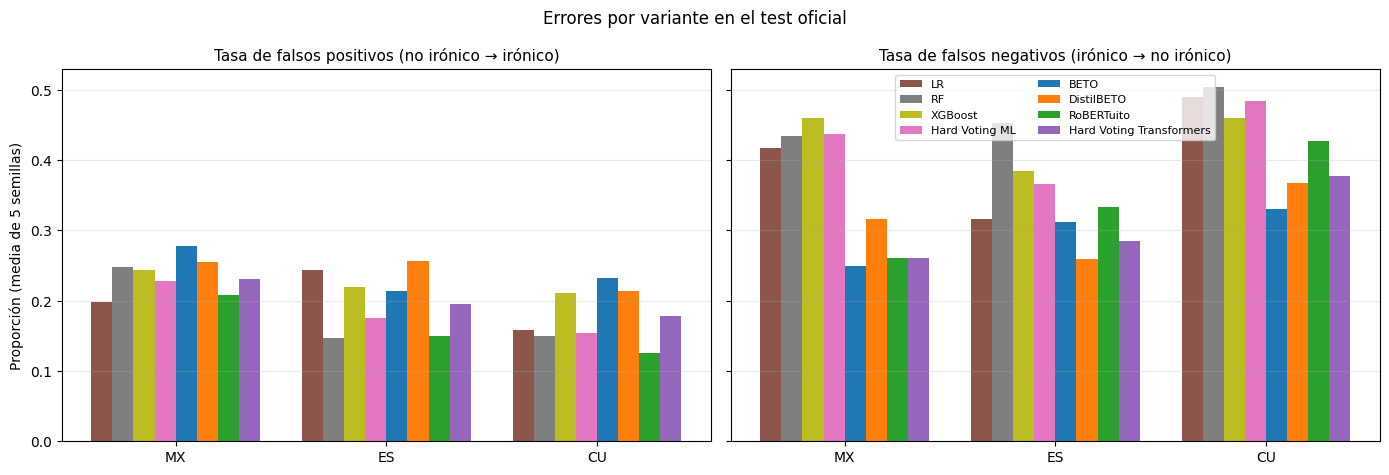

In [23]:
filas = []
for (variante, modelo), g in PRED.groupby(["variante", "modelo"]):
    cuentas = []
    for _, s in g.groupby("seed"):
        vn, fp, fn, vp = confusion_matrix(s["y_true"], s["y_pred"], labels=[0, 1]).ravel()
        cuentas.append((vp, vn, fp, fn))
    vp, vn, fp, fn = np.mean(cuentas, axis=0)
    filas.append({"variante": variante, "modelo": modelo, "VP": vp, "VN": vn, "FP": fp, "FN": fn,
                  "tasa_FP": fp / (fp + vn), "tasa_FN": fn / (fn + vp),
                  "FP_std": np.std([c[2] for c in cuentas], ddof=1) if len(cuentas) > 1 else np.nan,
                  "FN_std": np.std([c[3] for c in cuentas], ddof=1) if len(cuentas) > 1 else np.nan})
FPFN = pd.DataFrame(filas)
FPFN["modelo"] = pd.Categorical(FPFN["modelo"], ["LR", "RF", "XGBoost", "HardVoting", *TRANSFORMERS, "HardVotingTR"], ordered=True)
FPFN["variante"] = pd.Categorical(FPFN["variante"], VARIANTES, ordered=True)
FPFN = FPFN.sort_values(["variante", "modelo"]).reset_index(drop=True)
FPFN.to_csv(OUT_DIR / "tabla_fp_fn_test.csv", index=False)
display(FPFN.round(3))

modelos_fig = [m for m in ["LR", "RF", "XGBoost", "HardVoting", *TRANSFORMERS, "HardVotingTR"] if (FPFN["modelo"] == m).any()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ancho = 0.8 / len(modelos_fig)
for ax, (col, titulo) in zip(axes, [("tasa_FP", "Tasa de falsos positivos (no irónico → irónico)"),
                                    ("tasa_FN", "Tasa de falsos negativos (irónico → no irónico)")]):
    for k, modelo in enumerate(modelos_fig):
        valores = [FPFN.loc[(FPFN["variante"] == v) & (FPFN["modelo"] == modelo), col].squeeze() for v in VARIANTES]
        x = np.arange(len(VARIANTES)) + (k - (len(modelos_fig) - 1) / 2) * ancho
        ax.bar(x, valores, width=ancho, color=COLORES.get(modelo, "#999"),
               label={"HardVoting": "Hard Voting ML", "HardVotingTR": "Hard Voting Transformers"}.get(modelo, modelo))
    ax.set_xticks(range(len(VARIANTES)), [v.upper() for v in VARIANTES])
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Proporción (media de 5 semillas)")
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle("Errores por variante en el test oficial", fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "fp_fn_test.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "fp_fn_test.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)

## 13. Tuits que RoBERTuito falla siempre

Se listan los tuits que RoBERTuito clasifica mal en **las 5 semillas** (errores consistentes, no debidos al azar del entrenamiento), con su texto original, y se indica si el mejor modelo de ML de esa variante (sección 6) también los falla en todas sus semillas. Sirve para el análisis cualitativo de errores, especialmente en Cuba. Archivos: `errores_consistentes_robertuito.csv` y `resumen_errores_consistentes.csv`.

In [24]:
MODELO_ERRORES = "RoBERTuito"
filas, resumen_err = [], []
for variante in VARIANTES:
    g = PRED[(PRED["variante"] == variante) & (PRED["modelo"] == MODELO_ERRORES)]
    if g.empty:
        continue
    fallos = (g["y_true"] != g["y_pred"]).groupby(g["ID"]).agg(["sum", "count"])
    siempre = fallos.index[fallos["sum"] == fallos["count"]]
    ml_modelo = ML_EN_FIGURAS.get(variante)
    ml_siempre = set()
    if ml_modelo:
        gm = PRED[(PRED["variante"] == variante) & (PRED["modelo"] == ml_modelo)]
        fm = (gm["y_true"] != gm["y_pred"]).groupby(gm["ID"]).agg(["sum", "count"])
        ml_siempre = set(fm.index[fm["sum"] == fm["count"]])
    textos = pd.read_csv(DATA_DIR / "transformers" / f"test_transformers_{variante}.csv", dtype={"ID": str}).set_index("ID")
    etiquetas = g.drop_duplicates("ID").set_index("ID")["y_true"]
    for id_ in siempre:
        filas.append({"variante": variante, "ID": id_,
                      "tipo_error": "FN (irónico no detectado)" if etiquetas[id_] == 1 else "FP (falsa ironía)",
                      f"{ml_modelo or 'ML'}_tambien_falla": id_ in ml_siempre,
                      "coincide_train": id_ in IDS_COINCIDENTES.get(variante, set()),
                      "mensaje_original": textos.loc[id_, "MESSAGE"] if id_ in textos.index else ""})
    tipos = pd.Series([etiquetas[i] for i in siempre])
    resumen_err.append({"variante": variante, "errores_consistentes": len(siempre),
                        "FN": int((tipos == 1).sum()), "FP": int((tipos == 0).sum()),
                        "ml_comparado": ml_modelo, "tambien_falla_ml": len(set(siempre) & ml_siempre),
                        "pct_compartidos": (len(set(siempre) & ml_siempre) / len(siempre)) if len(siempre) else np.nan})
ERRORES = pd.DataFrame(filas)
RESUMEN_ERR = pd.DataFrame(resumen_err)
ERRORES.to_csv(OUT_DIR / "errores_consistentes_robertuito.csv", index=False)
RESUMEN_ERR.to_csv(OUT_DIR / "resumen_errores_consistentes.csv", index=False)
display(RESUMEN_ERR.round(3))
with pd.option_context("display.max_colwidth", None):
    for variante in VARIANTES:
        sub = ERRORES[ERRORES["variante"] == variante]
        print(f"\n{variante.upper()} — primeros ejemplos ({len(sub)} errores consistentes):")
        display(sub.head(8)[["tipo_error", "mensaje_original"]])

,variante,errores_consistentes,FN,FP,ml_comparado,tambien_falla_ml,pct_compartidos
0,mx,87,33,54,LR,44,0.506
1,es,92,52,40,LR,59,0.641
2,cu,98,64,34,RF,58,0.592



MX — primeros ejemplos (87 errores consistentes):


,tipo_error,mensaje_original
0,FP (falsa ironía),Sip te traje un llavero! Jajajaja
1,FP (falsa ironía),seguramente andabas ahi woowwwww @mando_rdz
2,FP (falsa ironía),"La tierra es plana. Todos los que mandan en el mundo, realmente son lagartos. Y la cerveza sin alcohol NO sabe culera!"
3,FP (falsa ironía),Mejor que con Peña y su compadre huachocolero igual que su jefe de guarros que era el de seguridad de Pemex 😂😂😂
4,FN (irónico no detectado),"@IlhuiM que se vayan a legislar a Venezuela, le harían muy bien al país jaja"
5,FP (falsa ironía),"De los creadores de la teoría de la Tierra Plana, llega..."
6,FP (falsa ironía),Pobres chilangos.... Pero ustedes votaron por ellos..... Aguantensen
7,FN (irónico no detectado),"Totalmente de acuerdo. Al extranjero solo tienen que ir funcionarios a compras sin licitación y fuera de NOM. Y también Noroñas a Nueva York y a Caracas, que es casi lo mismo"



ES — primeros ejemplos (92 errores consistentes):


,tipo_error,mensaje_original
87,FP (falsa ironía),"@alonsokas1 Por cierto, además de tierraplanistas somos antievolucionistas"
88,FP (falsa ironía),"@Q_E_D___ @contrapolitic Ese manual de resistencia de Pedro Sánchez, será un manual de su resistencia en el poder por el cual el pueblo NO LE VOTÓ. No será de la misma calidad que tu libro que de seguro tendrá buenos argumentos en cuanto pueda compro el libro. QUIEN ESTÁ DETRÁS ÁNIMO 👍"
89,FP (falsa ironía),"Ahora que se ha puesto de moda este apellido, Bastarreche. Veamos de quien es nieto el juez en cuestión que ha paralizado la exhumación de Franco: \n\nLA MASACRE DE LA CARRETERA MÁLAGA - ALMERÍA\nEl Almirante Bastarreche,1º por la izquierda,\njunto a altos cargos del ejército nazi. https://t.co/2vDU84Ex7Z"
90,FP (falsa ironía),Cogieron al clásico estereotipo vasco 😂😂😂 #VenACenar289
91,FN (irónico no detectado),@RadioCarmena Lávese la boca para hablar de @Pablo_Iglesias_ . Este tipo ha cambiado pañales durante 3 meses. Está preparado para llevar un país. https://t.co/HXab2zu91F
92,FP (falsa ironía),¡FRANCO VUELVE A GANAR A LOS ROJOS HASTA DESPUÉS DE MUERTO! LA JUSTICIA SUSPENDE LA EXHUMACIÓN DEL CAUDILLO https://t.co/k7GnAP3UiA
93,FN (irónico no detectado),Grezzi el concejal visionario del ayuntamiento de Valencia. \nManda 🥚🥚 !!! https://t.co/w8d7wgHUXI
94,FN (irónico no detectado),"Joan Tardá, lider independentista, con:\n- Otegi: Secuestró y torturó a Luis Abaitúa.\n- Sastre: Adosó una bomba lapa en el pecho a José María Bultó y lo reventó ante su familia.\nPero el fascista eres tú... https://t.co/pOZ7k8rCH4"



CU — primeros ejemplos (98 errores consistentes):


,tipo_error,mensaje_original
179,FN (irónico no detectado),"?Por lo visto,los partidarios de Industriales son fiel reflejo de ese equipo: arrogantes y prepotentes,sin cultura deportiva .nosotros ,los guajiros reconocemos a los adversarios que no son ni prepotentes ni arrogantes."
180,FP (falsa ironía),Qué falta de respeto utilizar frases irónicas para criticar al Cro. René por su decisión de utilizar sus 15 CUC del almuerzo para sufragar su instalación a internet. Eso demuestra la mente estrecha que tienen muchos comentaristas. René: oídos sordos!!!
181,FN (irónico no detectado),"la pregunta es los que crearon tuvieron la genial idea, pero olvidaron el salario promedio de la sociedad donde lo van a ofrecer? o sencillamente no es ese el tema? cual es el tema recaudar divisas? y quien piensa en los trabajadores, quien defiende sus intereses?"
182,FP (falsa ironía),"Por favor, yo solo tengo una pregunta a los panelistas.\n¿La corporación CIMEX es auditada por la ??????????? ??????? ?? ?? ??????????"
183,FP (falsa ironía),"Ladyrene, está muy bonito tu tatuaje ."
184,FP (falsa ironía),"Yaima, Yaima, basta."
185,FN (irónico no detectado),"?Siendo un buen equipo,Industriales es rechazado por excepto los capitalinos,por su bien ganada historia de arrogancia y prepotencia, siendo ademas aupados por los periodistas deportivos y coloco esa palabra entre comillas,porque un Periodista debe ser imparcial en sus juicios."
186,FN (irónico no detectado),"Cubano: quién dice que se le ha puesto nauta hogar a casi todas las viviendas de las capitales provinciales? Por favor deme el link de dónde leyó esa información para ver si me pusieron tambien, al menos en estadísticas."


## 14. Archivos de las secciones 12 y 13

Además de los de la sección 11: `tabla_fp_fn_test.csv`, `fp_fn_test.png/.pdf`, `errores_consistentes_robertuito.csv` y `resumen_errores_consistentes.csv`.